# Telco Customer Churn: Predictive Model

The SQL risk score and the Power BI dashboard explain **who has churned**. This notebook asks the next question: **can we identify customers likely to churn before they leave?**

**Contents**
1. Validate the rule-based risk score (why `MonthlyCharges` was dropped)
2. Train and compare three machine-learning models
3. Evaluate the chosen model on held-out data
4. What drives the model's predictions?
5. Business value: how many churners does targeting catch?
6. Score current customers and size the revenue at risk
7. Conclusions

**Data:** `Data/telco_churn_clean.csv` (7,032 customers, produced by `Python/prepare_data.py`).

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option('display.max_columns', None)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e6e6', 'figure.dpi': 100})

# One colour per series, used consistently in every chart
BLUE, ORANGE, AQUA, GRAY = '#257de0', '#f47230', '#00b894', '#999999'
SEED = 42

df = pd.read_csv(Path('..') / 'Data' / 'telco_churn_clean.csv')
print(f"{len(df):,} customers, churn rate {df['churns'].mean():.2%}")

7,032 customers, churn rate 26.58%

## 1. Validate the rule-based risk score

The SQL analysis built a transparent score: one point for each churn signal. Version 1 had 4 signals, version 2 added three more, and the final version drops `MonthlyCharges > 75`. ROC AUC measures how well a score ranks churners above non-churners (0.5 = random, 1.0 = perfect).

In [2]:
signals = {
    'Month-to-month':   df['Contract'] == 'Month-to-month',
    'Fiber optic':      df['InternetService'] == 'Fiber optic',
    'Electronic check': df['PaymentMethod'] == 'Electronic check',
    'No tech support':  df['TechSupport'] == 'No',
    'No online security': df['OnlineSecurity'] == 'No',
    'Tenure <= 6':      df['tenure'] <= 6,
}
score_final = sum(s.astype(int) for s in signals.values())
score_v2 = score_final + (df['MonthlyCharges'] > 75).astype(int)
score_v1 = sum(signals[k].astype(int) for k in ['Month-to-month', 'Fiber optic', 'Electronic check', 'No tech support'])

assert (score_final == df['risk_score']).all()   # matches the column in the clean CSV

pd.DataFrame({
    'signals': [4, 7, 6],
    'ROC AUC': [roc_auc_score(df['churns'], s) for s in (score_v1, score_v2, score_final)],
}, index=['v1', 'v2 (v1 + tenure, online security, MonthlyCharges > 75)', 'final (v2 without MonthlyCharges)']).round(3)

,signals,ROC AUC
v1,4,0.800
"v2 (v1 + tenure, online security, MonthlyCharges > 75)",7,0.817
final (v2 without MonthlyCharges),6,0.825


In [3]:
# Leave-one-out check: AUC of the final score after removing each signal in turn
loo = {name: roc_auc_score(df['churns'], score_final - s.astype(int)) for name, s in signals.items()}
pd.Series(loo, name='AUC without this signal').sort_values().round(3).to_frame()

,AUC without this signal
Month-to-month,0.807
Tenure <= 6,0.808
Fiber optic,0.817
No online security,0.821
Electronic check,0.822
No tech support,0.823


Dropping `MonthlyCharges > 75` **raises** AUC from 0.817 to 0.825. Price overlaps with fiber optic service (fiber plans are the expensive ones), so it added noise rather than new information. Removing any of the six remaining signals lowers AUC, so each one contributes.

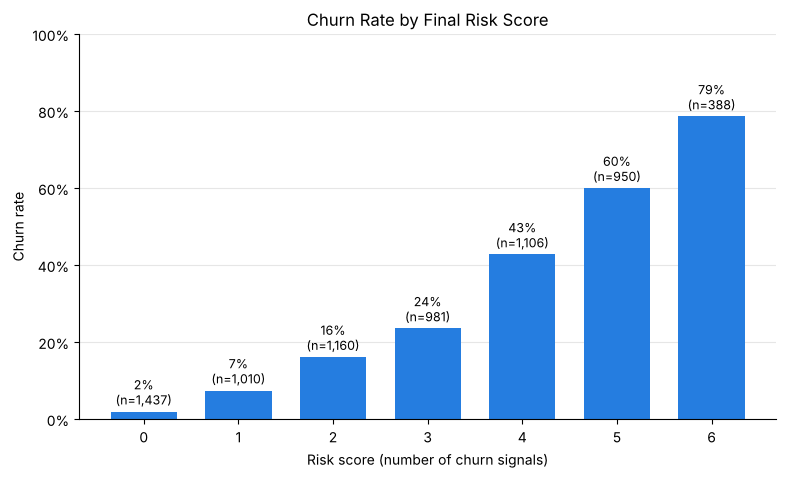

In [4]:
by_score = df.groupby('risk_score')['churns'].agg(churn_rate='mean', customers='size')

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(by_score.index, by_score['churn_rate'], color=BLUE, width=0.7, zorder=2)
ax.bar_label(bars, labels=[f"{r:.0%}\n(n={n:,})" for r, n in by_score.itertuples(index=False)],
             padding=3, fontsize=9)
ax.set_title('Churn Rate by Final Risk Score')
ax.set_xlabel('Risk score (number of churn signals)')
ax.set_ylabel('Churn rate')
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.grid(axis='x', visible=False)
plt.show()

## 2. Train and compare models

- **Features:** all 19 customer attributes. `risk_score` and `tenure_group` are left out because they are derived from these attributes.
- **Split:** 80% training / 20% test, stratified so both keep the 26.6% churn rate. The test set is used only once, for the final evaluation.
- **Model selection:** 5-fold cross-validated ROC AUC on the training set.

In [5]:
y = df['churns']
X = df.drop(columns=['customerID', 'churns', 'risk_score', 'tenure_group'])

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,} customers ({y_train.mean():.1%} churn)")
print(f"Test:  {len(X_test):,} customers ({y_test.mean():.1%} churn)")

Train: 5,625 customers (26.6% churn)
Test:  1,407 customers (26.6% churn)

In [6]:
preprocess = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cat_cols),
])

models = {
    'Logistic regression': LogisticRegression(max_iter=2000),
    'Random forest': RandomForestClassifier(n_estimators=400, min_samples_leaf=10, random_state=SEED, n_jobs=-1),
    'Gradient boosting': HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_depth=3, random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    cv_results[name] = {'CV ROC AUC (mean)': scores.mean(), 'CV ROC AUC (std)': scores.std()}

pd.DataFrame(cv_results).T.round(3)

,CV ROC AUC (mean),CV ROC AUC (std)
Logistic regression,0.846,0.005
Random forest,0.849,0.005
Gradient boosting,0.849,0.004


All three models land within 0.003 AUC of each other, well inside one standard deviation. **Logistic regression is chosen**: it performs as well as the tree-based models, its coefficients are directly interpretable, and it is easy to explain to a business audience.

## 3. Evaluate on the held-out test set

In [7]:
fitted = {}
test_proba = {}
for name, model in models.items():
    fitted[name] = Pipeline([('prep', preprocess), ('model', model)]).fit(X_train, y_train)
    test_proba[name] = fitted[name].predict_proba(X_test)[:, 1]

# The rule-based score is evaluated on the same customers as a baseline
test_proba['Rule-based risk score'] = df.loc[X_test.index, 'risk_score'].to_numpy()

pd.DataFrame({
    name: {'ROC AUC': roc_auc_score(y_test, p), 'PR AUC': average_precision_score(y_test, p)}
    for name, p in test_proba.items()
}).T.round(3)

,ROC AUC,PR AUC
Logistic regression,0.836,0.623
Random forest,0.837,0.640
Gradient boosting,0.838,0.653
Rule-based risk score,0.815,0.564


PR AUC (average precision) focuses on the churn class; a random guess would score 0.266, the churn rate.

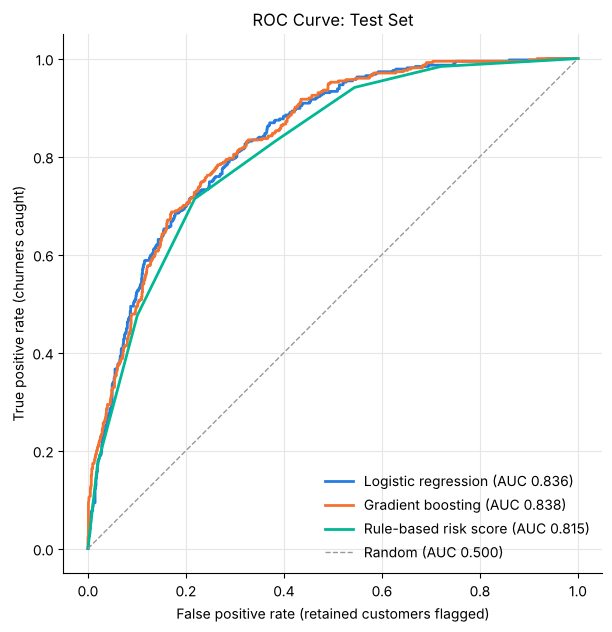

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
for name, color in [('Logistic regression', BLUE), ('Gradient boosting', ORANGE), ('Rule-based risk score', AQUA)]:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC {roc_auc_score(y_test, test_proba[name]):.3f})")
ax.plot([0, 1], [0, 1], color=GRAY, linestyle='--', linewidth=1, label='Random (AUC 0.500)')
ax.set_title('ROC Curve: Test Set')
ax.set_xlabel('False positive rate (retained customers flagged)')
ax.set_ylabel('True positive rate (churners caught)')
ax.set_aspect('equal')
ax.legend(loc='lower right', frameon=False)
plt.show()

The simple 6-signal score already captures most of the signal (AUC 0.815). The model adds about 0.02 AUC and, more usefully, produces a **probability** for every customer instead of 7 coarse levels, so customers can be ranked individually.

### Choosing a decision threshold

The default threshold of 0.5 favours accuracy, but missing a churner costs more than contacting a customer who would have stayed. The threshold is chosen on **out-of-fold training predictions** (never on the test set) to maximise F1, the balance of precision and recall.

In [9]:
final_model = fitted['Logistic regression']

oof = cross_val_predict(Pipeline([('prep', preprocess), ('model', LogisticRegression(max_iter=2000))]),
                        X_train, y_train, cv=cv, method='predict_proba')[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1])
threshold = thresholds[np.nanargmax(f1)]
print(f"Chosen threshold: {threshold:.2f}")

Chosen threshold: 0.32

In [10]:
p_test = test_proba['Logistic regression']
for label, t in [('Default threshold 0.50', 0.5), (f'Chosen threshold {threshold:.2f}', threshold)]:
    pred = (p_test >= t).astype(int)
    print(label)
    print(classification_report(y_test, pred, target_names=['Retained', 'Churned'], digits=3))

Default threshold 0.50
              precision    recall  f1-score   support

    Retained      0.852     0.888     0.870      1033
     Churned      0.650     0.575     0.610       374

    accuracy                          0.805      1407
   macro avg      0.751     0.731     0.740      1407
weighted avg      0.798     0.805     0.801      1407

Chosen threshold 0.32
              precision    recall  f1-score   support

    Retained      0.887     0.760     0.819      1033
     Churned      0.525     0.733     0.612       374

    accuracy                          0.753      1407
   macro avg      0.706     0.746     0.715      1407
weighted avg      0.791     0.753     0.764      1407

In [11]:
pred = (p_test >= threshold).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, pred),
                  index=['Actual: retained', 'Actual: churned'],
                  columns=['Predicted: retained', 'Predicted: churned'])
cm

,Predicted: retained,Predicted: churned
Actual: retained,785,248
Actual: churned,100,274


## 4. What drives the predictions?

**Permutation importance** shuffles one attribute at a time in the test set and measures how much ROC AUC drops. A large drop means the model relies on that attribute. It is measured on the original attributes, so one-hot columns are grouped back together.

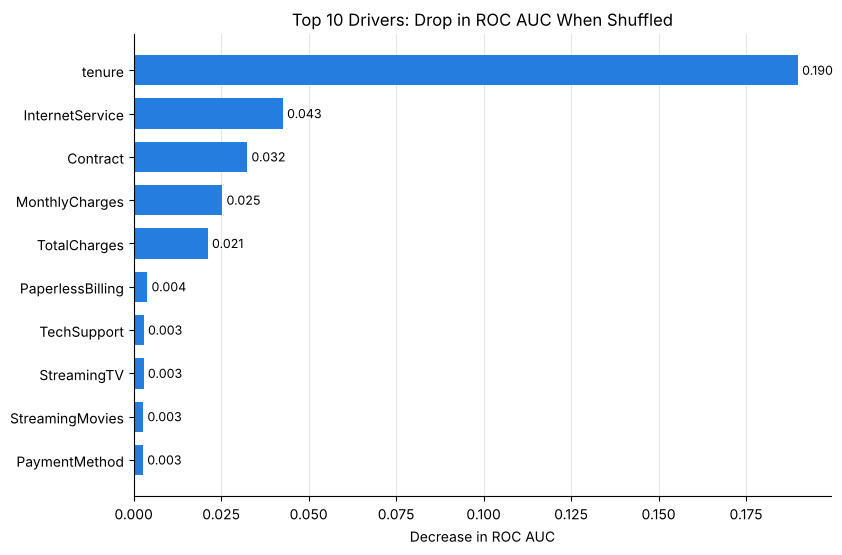

In [12]:
perm = permutation_importance(final_model, X_test, y_test, scoring='roc_auc',
                              n_repeats=20, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
top = importance.tail(10)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top.index, top.values, color=BLUE, height=0.7, zorder=2)
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_title('Top 10 Drivers: Drop in ROC AUC When Shuffled')
ax.set_xlabel('Decrease in ROC AUC')
ax.grid(axis='y', visible=False)
plt.show()

In [13]:
# Odds ratios from the logistic regression (numeric features: per 1 standard deviation).
# Every category keeps its own column, so compare categories of the same attribute,
# e.g. Contract_Month-to-month vs Contract_Two year.
feature_names = final_model.named_steps['prep'].get_feature_names_out()
coefs = final_model.named_steps['model'].coef_[0]
odds = pd.Series(np.exp(coefs), index=[f.split('__', 1)[1] for f in feature_names], name='odds_ratio')

key_features = ['tenure', 'MonthlyCharges', 'TotalCharges',
                'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year',
                'InternetService_Fiber optic', 'InternetService_DSL',
                'PaymentMethod_Electronic check', 'PaymentMethod_Credit card (automatic)',
                'TechSupport_No', 'TechSupport_Yes', 'OnlineSecurity_No', 'OnlineSecurity_Yes',
                'PaperlessBilling_Yes', 'SeniorCitizen_1']
odds[key_features].round(2).to_frame()

,odds_ratio
tenure,0.26
MonthlyCharges,0.57
TotalCharges,1.92
Contract_Month-to-month,1.77
Contract_One year,0.82
Contract_Two year,0.44
InternetService_Fiber optic,1.74
InternetService_DSL,0.52
PaymentMethod_Electronic check,1.16
PaymentMethod_Credit card (automatic),0.82


- **Tenure is by far the strongest predictor:** shuffling it costs 0.19 AUC. Each extra standard deviation of tenure (about 2 years) cuts the odds of churn by roughly 75% (odds ratio 0.26).
- **Contract and internet service come next.** Month-to-month customers have about 4x the churn odds of two-year customers (1.77 vs 0.44), and fiber optic customers about 3x those of DSL customers (1.74 vs 0.52), even after accounting for price. That points to a service-quality or competition issue with fiber rather than cost.
- **Some EDA drivers mostly overlap with these.** Once tenure, contract and internet service are known, payment method, tech support and online security add little (odds ratios between 0.8 and 1.2). Electronic-check payers and customers without support churn more largely because they tend to be new, month-to-month, fiber customers. These remain good flags for targeting, but are weaker as separate causes.
- `MonthlyCharges`, `TotalCharges` and `tenure` are strongly correlated (r = 0.65 to 0.83), so their individual odds ratios should not be read in isolation; permutation importance is the more reliable ranking.

## 5. Business value: how many churners does targeting catch?

A retention team cannot call everyone. The **cumulative gains curve** shows the share of all churners caught when contacting the top X% of customers ranked by predicted risk.

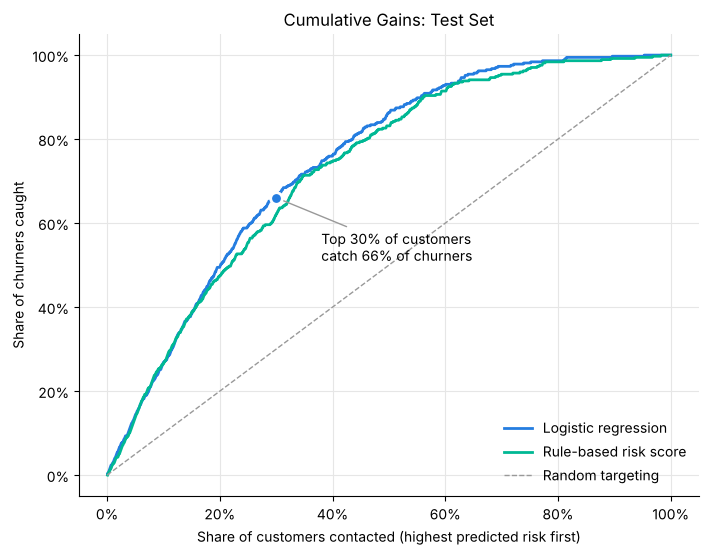

In [14]:
def gains(y_true, score):
    order = np.argsort(-score, kind='stable')
    caught = np.cumsum(np.asarray(y_true)[order]) / np.sum(y_true)
    contacted = np.arange(1, len(order) + 1) / len(order)
    return contacted, caught

fig, ax = plt.subplots(figsize=(8, 6))
for name, color in [('Logistic regression', BLUE), ('Rule-based risk score', AQUA)]:
    x, g = gains(y_test, test_proba[name])
    ax.plot(x, g, color=color, linewidth=2, label=name)
ax.plot([0, 1], [0, 1], color=GRAY, linestyle='--', linewidth=1, label='Random targeting')

x, g = gains(y_test, test_proba['Logistic regression'])
k = int(0.3 * len(x)) - 1
ax.scatter(x[k], g[k], color=BLUE, s=70, zorder=5, edgecolor='white', linewidth=2)
ax.annotate(f"Top 30% of customers\ncatch {g[k]:.0%} of churners", xy=(x[k], g[k]),
            xytext=(x[k] + 0.08, g[k] - 0.15), fontsize=10, arrowprops={'arrowstyle': '-', 'color': GRAY})
ax.set_title('Cumulative Gains: Test Set')
ax.set_xlabel('Share of customers contacted (highest predicted risk first)')
ax.set_ylabel('Share of churners caught')
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc='lower right', frameon=False)
plt.show()

Within each risk-score level, customers are tied, so the rule-based curve takes them in arbitrary order; the model separates them.

In [15]:
rows = []
for share in [0.1, 0.2, 0.3, 0.4]:
    row = {'customers contacted': f"top {share:.0%}"}
    for name in ['Logistic regression', 'Rule-based risk score']:
        x, g = gains(y_test, test_proba[name])
        row[name] = g[int(share * len(x)) - 1]
    row['Random targeting'] = share
    rows.append(row)
(pd.DataFrame(rows).set_index('customers contacted') * 100).round(1).add_suffix(' (% of churners caught)')

,Logistic regression (% of churners caught),Rule-based risk score (% of churners caught),Random targeting (% of churners caught)
customers contacted,,,
top 10%,26.7,26.5,10.0
top 20%,49.5,47.3,20.0
top 30%,66.0,62.0,30.0
top 40%,75.9,74.6,40.0


Contacting the **top 30%** of customers ranked by the model reaches roughly **two-thirds of all churners**, more than twice what random targeting would catch. Because the rule-based score has only 7 levels, it cannot rank customers within a level, so the model is more efficient for small, focused campaigns.

## 6. Score current customers and size the revenue at risk

To rank customers who are **still active**, every customer is scored with **out-of-fold** predictions: each customer's probability comes from a model trained without them, so the score is not inflated by the model having seen their outcome.

In [16]:
final_pipe = Pipeline([('prep', preprocess), ('model', LogisticRegression(max_iter=2000))])
df['churn_probability'] = cross_val_predict(final_pipe, X, y, cv=cv, method='predict_proba')[:, 1]

active = df[df['churns'] == 0]
high_risk = active[active['churn_probability'] >= threshold]

summary = pd.Series({
    'Active customers': len(active),
    'High-risk active customers (p >= threshold)': len(high_risk),
    'Share of active customers': f"{len(high_risk) / len(active):.1%}",
    'Their monthly revenue ($)': f"{high_risk['MonthlyCharges'].sum():,.0f}",
    'Share of active monthly revenue': f"{high_risk['MonthlyCharges'].sum() / active['MonthlyCharges'].sum():.1%}",
})
summary.to_frame('value')

,value
Active customers,5163
High-risk active customers (p >= threshold),1134
Share of active customers,22.0%
Their monthly revenue ($),"85,969"
Share of active monthly revenue,27.2%


In [17]:
cols = ['customerID', 'Contract', 'InternetService', 'PaymentMethod', 'tenure',
        'MonthlyCharges', 'risk_score', 'churn_probability']
(high_risk.sort_values(['churn_probability', 'MonthlyCharges'], ascending=False)[cols]
    .head(10).round({'churn_probability': 3}).reset_index(drop=True))

,customerID,Contract,InternetService,PaymentMethod,tenure,MonthlyCharges,risk_score,churn_probability
0,5150-ITWWB,Month-to-month,Fiber optic,Electronic check,3,94.85,6,0.835
1,2545-EBUPK,Month-to-month,Fiber optic,Electronic check,2,84.05,6,0.823
2,3320-VEOYC,Month-to-month,Fiber optic,Electronic check,14,95.60,5,0.807
3,6630-UJZMY,Month-to-month,Fiber optic,Electronic check,4,83.25,6,0.802
4,8161-QYMTT,Month-to-month,Fiber optic,Electronic check,7,94.10,5,0.799
5,4912-PIGUY,Month-to-month,Fiber optic,Electronic check,1,84.60,6,0.798
6,4847-TAJYI,Month-to-month,Fiber optic,Electronic check,6,89.35,6,0.796
7,5935-FCCNB,Month-to-month,Fiber optic,Electronic check,17,94.20,5,0.795
8,2235-DWLJU,Month-to-month,DSL,Electronic check,6,44.40,5,0.791
9,4115-NZRKS,Month-to-month,Fiber optic,Electronic check,7,89.15,5,0.790


In [18]:
high_risk.groupby('tenure_group')['MonthlyCharges'].agg(customers='size', monthly_revenue='sum') \
    .reindex(['0-6 months', '7-12 months', '13-24 months', '25+ months']).round(0)

,customers,monthly_revenue
tenure_group,,
0-6 months,354,21734.0
7-12 months,199,13730.0
13-24 months,257,20462.0
25+ months,324,30044.0


## 7. Conclusions

1. **The simple risk score holds up.** Six yes/no signals rank customers almost as well as a full model (test ROC AUC 0.815 vs 0.836). Dropping `MonthlyCharges` from the score was the right call.
2. **Logistic regression is the recommended model.** It matches random forest and gradient boosting (CV ROC AUC about 0.85 for all three) while staying interpretable.
3. **Targeting is efficient.** Contacting the 30% highest-risk customers reaches about two-thirds of churners.
4. **Tenure, contract and fiber optic service are the core drivers.** When all attributes are considered together, payment method and missing support / security add little on top of them: they are markers of the same new, month-to-month, fiber customer profile.
5. **Action:** the high-risk active customers listed above represent recurring revenue worth protecting. Offering them a discounted 1- or 2-year contract, a switch to automatic payment, or a bundled security / tech support add-on targets exactly the drivers the model identified.

**Limitations:** this is a single snapshot with no dates, so the model cannot say *when* a customer will churn, and the retained customers flagged here are "look-alikes" of past churners rather than confirmed future churners. A production version would be retrained on monthly snapshots and validated on a later time period.